<a href="https://colab.research.google.com/github/Ayushmaantiwari/Digi_Analyser/blob/main/Digi_Analyser.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import cv2
import os

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Select GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [2]:
# MNIST normalization parameters
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)) # Mean and Std of MNIST dataset
])

# Download and load training and test datasets
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Hyperparameters
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 15

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 499kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.85MB/s]

Train samples: 60000, Test samples: 10000


In [3]:
class DigitMLP(nn.Module):
    def __init__(self, hidden_dim1=256, hidden_dim2=128, dropout_rate=0.2):
        super(DigitMLP, self).__init__()
        # Flatten 28x28 images into a 784 1D vector
        self.flatten = nn.Flatten()

        # Dense Network with BatchNorm and Dropout to prevent overfitting
        self.network = nn.Sequential(
            nn.Linear(28 * 28, hidden_dim1),
            nn.BatchNorm1d(hidden_dim1),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(hidden_dim1, hidden_dim2),
            nn.BatchNorm1d(hidden_dim2),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(hidden_dim2, 10)  # 10 output classes (digits 0-9)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)

model = DigitMLP().to(device)
print(model)

DigitMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_losses, test_losses = [], []
train_accuracies, test_accuracies = [], []

for epoch in range(EPOCHS):
    # Training Phase
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # Evaluation Phase
    model.eval()
    running_test_loss, correct_test, total_test = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_test_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_test += (preds == labels).sum().item()
            total_test += labels.size(0)

    epoch_test_loss = running_test_loss / total_test
    epoch_test_acc = (correct_test / total_test) * 100
    test_losses.append(epoch_test_loss)
    test_accuracies.append(epoch_test_acc)

    print(f"Epoch {epoch+1:02d}/{EPOCHS:02d} | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} - Test Acc: {epoch_test_acc:.2f}%")

Epoch 01/15 | Train Loss: 0.2630 - Train Acc: 92.63% | Test Loss: 0.0984 - Test Acc: 96.83%
Epoch 02/15 | Train Loss: 0.1241 - Train Acc: 96.14% | Test Loss: 0.0790 - Test Acc: 97.34%
Epoch 03/15 | Train Loss: 0.1001 - Train Acc: 96.86% | Test Loss: 0.0724 - Test Acc: 97.81%
Epoch 04/15 | Train Loss: 0.0825 - Train Acc: 97.41% | Test Loss: 0.0627 - Test Acc: 97.95%
Epoch 05/15 | Train Loss: 0.0705 - Train Acc: 97.73% | Test Loss: 0.0678 - Test Acc: 98.02%
Epoch 06/15 | Train Loss: 0.0616 - Train Acc: 97.99% | Test Loss: 0.0569 - Test Acc: 98.11%
Epoch 07/15 | Train Loss: 0.0577 - Train Acc: 98.13% | Test Loss: 0.0564 - Test Acc: 98.21%
Epoch 08/15 | Train Loss: 0.0514 - Train Acc: 98.30% | Test Loss: 0.0556 - Test Acc: 98.15%
Epoch 09/15 | Train Loss: 0.0469 - Train Acc: 98.44% | Test Loss: 0.0605 - Test Acc: 98.15%
Epoch 10/15 | Train Loss: 0.0468 - Train Acc: 98.44% | Test Loss: 0.0568 - Test Acc: 98.23%
Epoch 11/15 | Train Loss: 0.0424 - Train Acc: 98.57% | Test Loss: 0.0615 - Test 

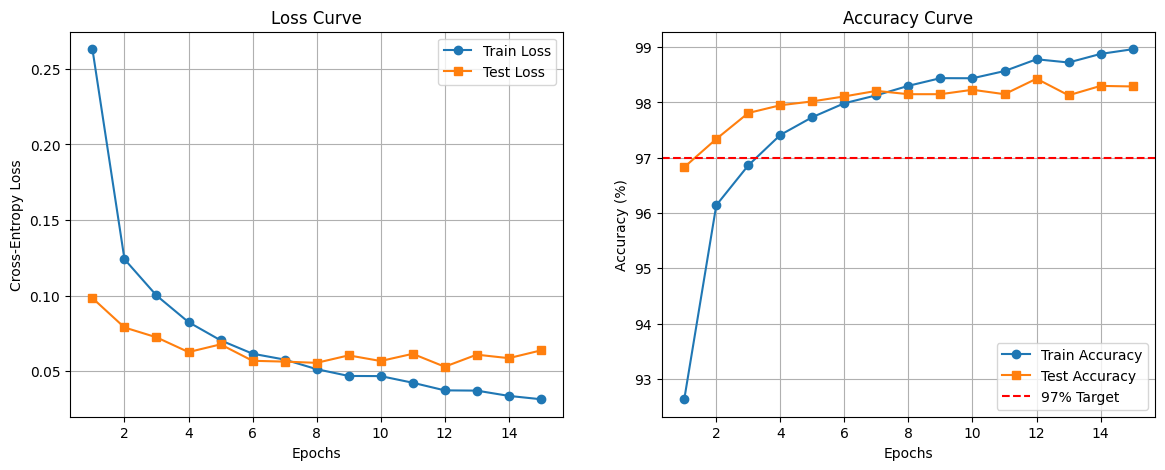

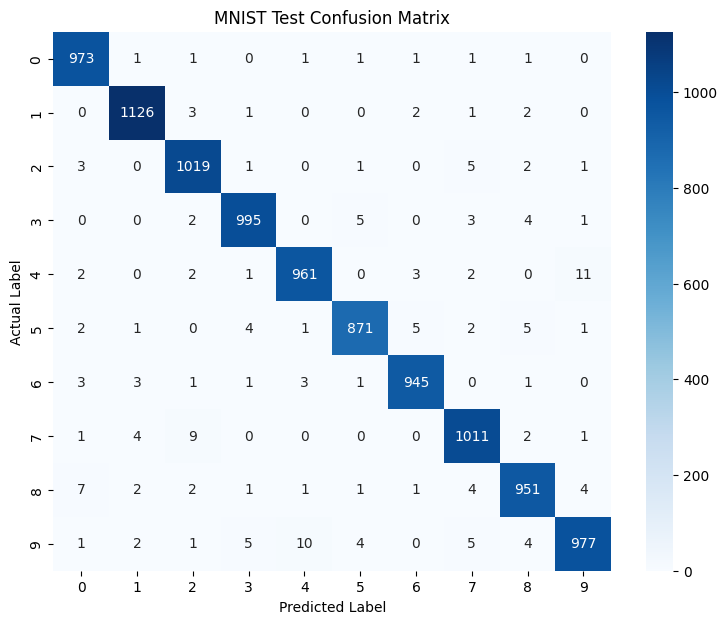


Classification Report:

              precision    recall  f1-score   support

           0     0.9808    0.9929    0.9868       980
           1     0.9886    0.9921    0.9903      1135
           2     0.9798    0.9874    0.9836      1032
           3     0.9861    0.9851    0.9856      1010
           4     0.9836    0.9786    0.9811       982
           5     0.9853    0.9765    0.9809       892
           6     0.9875    0.9864    0.9869       958
           7     0.9778    0.9835    0.9806      1028
           8     0.9784    0.9764    0.9774       974
           9     0.9809    0.9683    0.9746      1009

    accuracy                         0.9829     10000
   macro avg     0.9829    0.9827    0.9828     10000
weighted avg     0.9829    0.9829    0.9829     10000



In [7]:
# 1. Plot Training vs Test Metrics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, EPOCHS+1), train_losses, label='Train Loss', marker='o')
axes[0].plot(range(1, EPOCHS+1), test_losses, label='Test Loss', marker='s')
axes[0].set_title('Loss Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(range(1, EPOCHS+1), train_accuracies, label='Train Accuracy', marker='o')
axes[1].plot(range(1, EPOCHS+1), test_accuracies, label='Test Accuracy', marker='s')

# FIXED: Changed set_axhline to axhline
axes[1].axhline(y=97.0, color='r', linestyle='--', label='97% Target')

axes[1].set_title('Accuracy Curve')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True)

plt.show()

# 2. Confusion Matrix Computation
all_preds, all_labels = [], []
model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title('MNIST Test Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, digits=4))

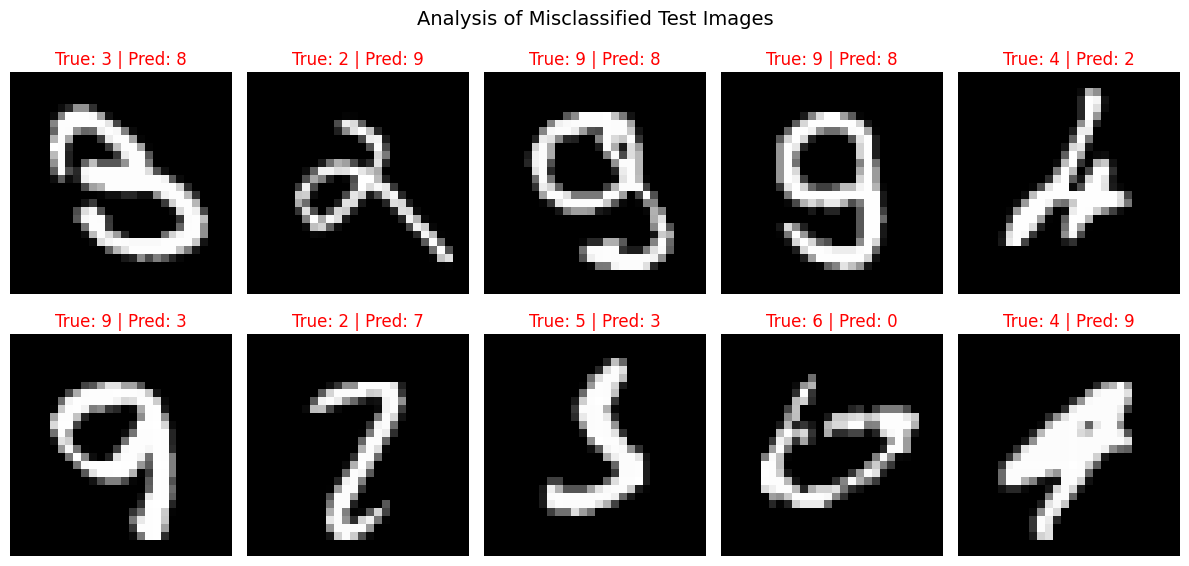

In [8]:
# Find and display misclassified samples
misclassified_indices = []

for idx, (label, pred) in enumerate(zip(all_labels, all_preds)):
    if label != pred:
        misclassified_indices.append(idx)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
fig.suptitle('Analysis of Misclassified Test Images', fontsize=14)

for i, ax in enumerate(axes.flat):
    if i < len(misclassified_indices):
        idx = misclassified_indices[i]
        img, true_label = test_dataset[idx]
        pred_label = all_preds[idx]

        # Un-normalize image back to 0-1 range for plotting
        img_unnorm = img.squeeze().numpy() * 0.3081 + 0.1307

        ax.imshow(img_unnorm, cmap='gray')
        ax.set_title(f"True: {true_label} | Pred: {pred_label}", color='red')
        ax.axis('off')

plt.tight_layout()
plt.show()

Model checkpoint saved successfully to mnist_mlp_model.pth
Reloaded model weights restored successfully.


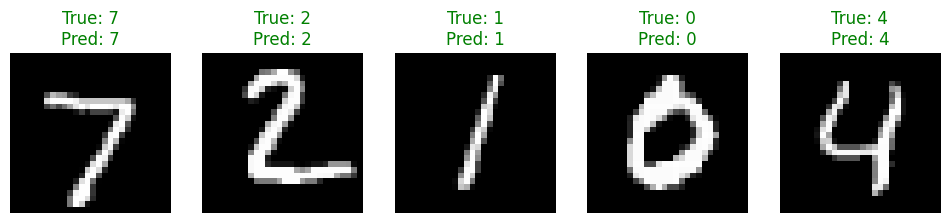

In [9]:
# Save model weights to disk
MODEL_PATH = "mnist_mlp_model.pth"
torch.save(model.state_dict(), MODEL_PATH)
print(f"Model checkpoint saved successfully to {MODEL_PATH}")

# Demonstrate Re-loading into a new instance
reloaded_model = DigitMLP().to(device)
reloaded_model.load_state_dict(torch.load(MODEL_PATH))
reloaded_model.eval()
print("Reloaded model weights restored successfully.")

# Validate Reloaded Model on Test Samples
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for idx in range(5):
    img, true_label = test_dataset[idx]

    # Inference
    input_tensor = img.unsqueeze(0).to(device)
    with torch.no_grad():
        output = reloaded_model(input_tensor)
        pred_label = torch.argmax(output, dim=1).item()

    img_unnorm = img.squeeze().numpy() * 0.3081 + 0.1307
    axes[idx].imshow(img_unnorm, cmap='gray')
    axes[idx].set_title(f"True: {true_label}\nPred: {pred_label}", color='green' if true_label==pred_label else 'red')
    axes[idx].axis('off')

plt.show()

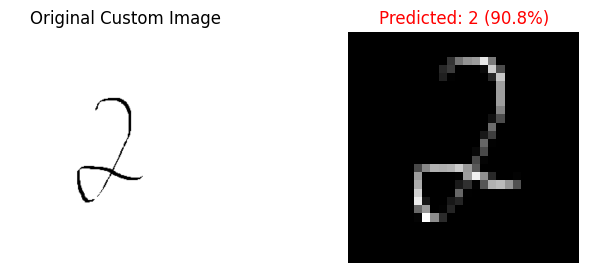

In [18]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import ndimage
import os

def get_best_shift(img):
    # Calculate center of mass of the digit
    cy, cx = ndimage.center_of_mass(img)
    rows, cols = img.shape

    # Calculate shift required to place center of mass at the image center (14, 14)
    shiftx = np.round(cols/2.0 - cx)
    shifty = np.round(rows/2.0 - cy)
    return shiftx, shifty

def shift_image(img, sx, sy):
    rows, cols = img.shape
    M = np.float32([[1, 0, sx], [0, 1, sy]])
    shifted = cv2.warpAffine(img, M, (cols, rows))
    return shifted

def predict_custom_image(image_path, model_instance):
    if not os.path.exists(image_path):
        print(f"Error: File not found at {image_path}")
        return

    # 1. Load image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    # 2. Invert colors (White background -> Black background)
    img_inverted = cv2.bitwise_not(img)

    # 3. Apply threshold to sharpen digit & remove noise
    _, img_thresh = cv2.threshold(img_inverted, 128, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

    # 4. Crop around bounding box of digit
    coords = cv2.findNonZero(img_thresh)
    x, y, w, h = cv2.boundingRect(coords)
    cropped = img_thresh[y:y+h, x:x+w]

    # 5. Fit digit inside a 20x20 box preserving aspect ratio
    if w > h:
        new_w = 20
        new_h = int(round(h * (20.0 / w)))
    else:
        new_h = 20
        new_w = int(round(w * (20.0 / h)))

    resized_digit = cv2.resize(cropped, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # 6. Pad canvas to 28x28
    canvas = np.zeros((28, 28), dtype=np.uint8)
    start_x = (28 - new_w) // 2
    start_y = (28 - new_h) // 2
    canvas[start_y:start_y+new_h, start_x:start_x+new_w] = resized_digit

    # 7. Align using Center of Mass
    sx, sy = get_best_shift(canvas)
    aligned_img = shift_image(canvas, sx, sy)

    # 8. Normalize using MNIST statistics
    img_normalized = (aligned_img / 255.0 - 0.1307) / 0.3081

    # 9. Convert to PyTorch Tensor
    tensor_input = torch.tensor(img_normalized, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

    # 10. Predict
    model_instance.eval()
    with torch.no_grad():
        output = model_instance(tensor_input)
        probabilities = torch.softmax(output, dim=1).squeeze().cpu().numpy()
        predicted_class = np.argmax(probabilities)
        confidence = probabilities[predicted_class] * 100

    # Display results
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    axes[0].imshow(img, cmap='gray')
    axes[0].set_title("Original Custom Image")
    axes[0].axis('off')

    axes[1].imshow(aligned_img, cmap='gray')
    axes[1].set_title(f"Predicted: {predicted_class} ({confidence:.1f}%)",
                      color='green' if predicted_class==7 else 'red')
    axes[1].axis('off')

    plt.show()

# Run prediction with updated pipeline
predict_custom_image("/content/2_017.png", reloaded_model)

In [19]:
!pip install -q gradio

In [26]:
def preprocess_image(img_input):
    if img_input is None:
        return None

    # 1. Unbox Gradio dictionary/sketchpad structures
    if isinstance(img_input, dict):
        img_array = img_input.get("composite", None)
        if img_array is None and "layers" in img_input and len(img_input["layers"]) > 0:
            img_array = img_input["layers"][0]
    else:
        img_array = img_input

    if img_array is None or not isinstance(img_array, np.ndarray):
        return None

    # 2. Extract single channel safely
    if img_array.ndim == 3:
        if img_array.shape[2] == 4:  # Handle RGBA from canvas
            # Use Alpha channel if drawing strokes are rendered on transparent canvas
            alpha = img_array[:, :, 3]
            if np.max(alpha) > 0:
                gray = alpha
            else:
                gray = cv2.cvtColor(img_array[:, :, :3], cv2.COLOR_RGB2GRAY)
        else:
            gray = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
    else:
        gray = img_array

    # 3. Ensure white digit on black background
    # If background is bright (white), invert it to black
    if np.mean(gray) > 127:
        gray = cv2.bitwise_not(gray)

    # 4. Threshold to remove background noise
    _, img_thresh = cv2.threshold(gray, 30, 255, cv2.THRESH_BINARY)

    # 5. Extract bounding box of digit strokes
    coords = cv2.findNonZero(img_thresh)
    if coords is None:
        return torch.zeros((1, 1, 28, 28), dtype=torch.float32)

    x, y, w, h = cv2.boundingRect(coords)
    cropped = img_thresh[y:y+h, x:x+w]

    # 6. Resize preserving aspect ratio into a 20x20 box
    if w > h:
        new_w = 20
        new_h = int(round(h * (20.0 / w)))
    else:
        new_h = 20
        new_w = int(round(w * (20.0 / h)))

    new_h = max(1, new_h)
    new_w = max(1, new_w)
    resized_digit = cv2.resize(cropped, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # 7. Pad onto 28x28 canvas
    canvas = np.zeros((28, 28), dtype=np.uint8)
    start_x = (28 - new_w) // 2
    start_y = (28 - new_h) // 2
    canvas[start_y:start_y+new_h, start_x:start_x+new_w] = resized_digit

    # 8. Shift by Center of Mass
    try:
        sx, sy = get_best_shift(canvas)
        aligned_img = shift_image(canvas, sx, sy)
    except Exception:
        aligned_img = canvas

    # 9. Normalize with MNIST statistics
    img_normalized = (aligned_img / 255.0 - 0.1307) / 0.3081

    return torch.tensor(img_normalized, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

In [28]:
import gradio as gr
import torch
import numpy as np
import cv2
from scipy import ndimage

# --- Helper Functions for MNIST Alignment ---
def get_best_shift(img):
    cy, cx = ndimage.center_of_mass(img)
    rows, cols = img.shape
    shiftx = np.round(cols / 2.0 - cx)
    shifty = np.round(rows / 2.0 - cy)
    return shiftx, shifty

def shift_image(img, sx, sy):
    rows, cols = img.shape
    M = np.float32([[1, 0, sx], [0, 1, sy]])
    return cv2.warpAffine(img, M, (cols, rows))

def preprocess_image(img_array):
    if img_array is None:
        return None

    # Handle dictionary output from gr.Sketchpad if passed directly
    if isinstance(img_array, dict):
        img_array = img_array.get("composite", img_array.get("layers", [None])[0])

    if img_array is None:
        return None

    # Convert to Grayscale
    if len(img_array.shape) == 3:
        gray = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
    else:
        gray = img_array

    # Auto-detect background color: MNIST requires white digits on a black background
    if np.mean(gray) > 127:
        gray = cv2.bitwise_not(gray)

    # Thresholding to remove noise
    _, img_thresh = cv2.threshold(gray, 50, 255, cv2.THRESH_BINARY)

    # Find bounding box
    coords = cv2.findNonZero(img_thresh)
    if coords is None:
        return torch.zeros((1, 1, 28, 28), dtype=torch.float32)

    x, y, w, h = cv2.boundingRect(coords)
    cropped = img_thresh[y:y+h, x:x+w]

    # Fit inside a 20x20 box preserving aspect ratio
    if w > h:
        new_w = 20
        new_h = int(round(h * (20.0 / w)))
    else:
        new_h = 20
        new_w = int(round(w * (20.0 / h)))

    resized_digit = cv2.resize(cropped, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # Pad onto a 28x28 canvas
    canvas = np.zeros((28, 28), dtype=np.uint8)
    start_x = (28 - new_w) // 2
    start_y = (28 - new_h) // 2
    canvas[start_y:start_y+new_h, start_x:start_x+new_w] = resized_digit

    # Shift based on center of mass
    sx, sy = get_best_shift(canvas)
    aligned_img = shift_image(canvas, sx, sy)

    # Normalize with MNIST statistics
    img_normalized = (aligned_img / 255.0 - 0.1307) / 0.3081

    # Tensor output shape (1, 1, 28, 28)
    return torch.tensor(img_normalized, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

# --- Core Prediction Logic ---
def classify_digit(input_image):
    if input_image is None:
        return {}

    tensor_input = preprocess_image(input_image)
    if tensor_input is None:
        return {}

    tensor_input = tensor_input.to(device)

    reloaded_model.eval()
    with torch.no_grad():
        output = reloaded_model(tensor_input)
        probabilities = torch.softmax(output, dim=1).squeeze().cpu().numpy()

    return {str(digit): float(prob) for digit, prob in enumerate(probabilities)}

# --- Gradio UI Layout with Upload Button & Canvas ---
with gr.Blocks(title="Handwritten Digit Classifier") as interface:
    gr.Markdown("# Handwritten Digit Classifier (MNIST MLP)")
    gr.Markdown("Draw a digit on the canvas or upload an image file from your device.")

    with gr.Row():
        with gr.Column():
            with gr.Tabs():
                with gr.TabItem("Draw Canvas"):
                    sketchpad_input = gr.Sketchpad(
                        label="Draw a Digit (0-9)",
                        type="numpy",
                        image_mode="L",
                        canvas_size=(280, 280)
                    )
                    draw_btn = gr.Button("Predict Drawing", variant="primary")

                with gr.TabItem("Upload Image"):
                    file_input = gr.Image(
                        label="Upload Digit Image",
                        type="numpy",
                        image_mode="L"
                    )
                    upload_btn = gr.Button("Predict Uploaded Image", variant="primary")

        with gr.Column():
            output_label = gr.Label(num_top_classes=3, label="Top 3 Predictions")

    # Connect event triggers
    sketchpad_input.change(fn=classify_digit, inputs=sketchpad_input, outputs=output_label)
    draw_btn.click(fn=classify_digit, inputs=sketchpad_input, outputs=output_label)

    file_input.change(fn=classify_digit, inputs=file_input, outputs=output_label)
    upload_btn.click(fn=classify_digit, inputs=file_input, outputs=output_label)

# Launch GUI
interface.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://85156d4dcac80631a9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/queueing.py", line 882, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/route_utils.py", line 410, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2330, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<9 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 1690, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        fn, *processed_input, limiter=self.limiter
        ^^^^^^^^^^^^^^

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://85156d4dcac80631a9.gradio.live
